# Traffic Volume Analysis for Stavanger

**Project:** Profiling traffic and accidents in Stavanger (Bachelor's project 2026)
**Data source:** Statens vegvesen, *Trafikkdata* ([dataset page](https://dataut.vegvesen.no/en/dataset/trafikkdata)), licensed under NLOD 2.0

This notebook downloads hourly traffic volumes from automatic counting stations in Stavanger, cleans them, and explores *when* and *where* traffic is heaviest. The cleaned daily table it produces is the traffic input for the accident model later in the project.

| Section | What happens |
|---|---|
| 1. Setup | Import libraries and set parameters |
| 2. Connect to the API | Send a first test query to the GraphQL API |
| 3. Counting stations | Find all operational stations in Stavanger |
| 4. Download hourly volumes | Fetch hourly counts per station, with caching |
| 5. Cleaning and features | Remove unreliable hours and add calendar columns |
| 6. Daily aggregation | Build daily traffic per station (ADT) |
| 7. Visualizations | Eight charts, each with a short explanation |
| 8. Key insights | Numeric summary of the findings |
| 9. Save outputs | Write CSV files for the modelling stage |

## 1. Setup

### 1.1 Libraries
Install once in the environment if needed:
```
pip install requests pandas matplotlib seaborn
```
- `requests` sends HTTP requests to the API.
- `pandas` holds and transforms the tabular data.
- `matplotlib` and `seaborn` draw the charts.

In [1]:
import json
import logging
import time
from datetime import date, datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import requests
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", datefmt="%H:%M:%S")
logging.getLogger("matplotlib").setLevel(logging.WARNING)
log = logging.getLogger("traffic")

pd.set_option("display.max_columns", 30)

### 1.2 Parameters
Change these values to control the analysis. Everything below reads from this cell.

- **START_DATE / END_DATE:** the period to download. Hourly data is heavy (about 8,760 rows per station per year), so start with a short period while testing.
- **MAX_POINTS:** limits the number of stations. `None` means all stations. Use a small number such as `3` for a quick first run.
- **MIN_COVERAGE_PCT:** a station sometimes records only part of an hour (sensor faults, roadworks). Hours with coverage below this threshold are removed.
- **County and municipality numbers:** Rogaland is county `11`. Stavanger is municipality `1103`.

In [2]:
# Analysis period (END_DATE is exclusive)
START_DATE = "2023-01-01"
END_DATE = "2025-12-31"

# Area of interest
COUNTY_NUMBER = 11          # Rogaland
MUNICIPALITY_NUMBER = 1103  # Stavanger; set to None for the whole county

# Download and quality settings
MAX_POINTS = None           # e.g. 3 for a quick test run
REFRESH_CACHE = False       # True forces a fresh download
MIN_COVERAGE_PCT = 50.0     # Minimum share of the hour that must be recorded
MIN_VALID_HOURS_PER_DAY = 20
HEAVY_VEHICLE_MIN_LENGTH = 5.6  # metres, Statens vegvesen convention

# API settings
API_URL = "https://trafikkdata-api.atlas.vegvesen.no/"
REQUEST_PAUSE_S = 0.2       # Short pause between requests to be polite to the API
TIMEZONE = ZoneInfo("Europe/Oslo")

# Folder layout (relative to this notebook)
PROJECT_ROOT = Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "traffic"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "figures" / "traffic"
for folder in (RAW_DIR, PROCESSED_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

START = datetime.fromisoformat(START_DATE).replace(tzinfo=TIMEZONE)
END = datetime.fromisoformat(END_DATE).replace(tzinfo=TIMEZONE)
assert END > START, "END_DATE must be after START_DATE"
print(f"Period: {START:%Y-%m-%d} to {END:%Y-%m-%d}  |  Output folder: {PROJECT_ROOT}")

Period: 2023-01-01 to 2025-12-31  |  Output folder: x:\BachelorsProject2026


### 1.3 Chart style
One shared style keeps all figures consistent in the report: a light background, quiet grid lines, and a small colour palette. Blue is the main series colour, orange the comparison colour, and a light-to-dark blue scale is used for magnitude (heatmap, map).

In [3]:
SERIES_BLUE = "#2a78d6"
SERIES_ORANGE = "#eb6834"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID_COLOUR = "#e4e3df"
SURFACE = "#fcfcfb"
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
WEEKDAY_ORDER = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID_COLOUR, "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY, "axes.titleweight": "semibold",
    "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID_COLOUR, "grid.linewidth": 0.8,
    "xtick.color": TEXT_SECONDARY, "ytick.color": TEXT_SECONDARY,
    "lines.linewidth": 2, "legend.frameon": False,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})


def thousands(ax, axis="y"):
    # Format tick labels as 12 500 instead of 12500.
    fmt = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def save(fig, name):
    # Save a figure as PNG in the figures folder and show it in the notebook.
    path = FIGURE_DIR / f"{name}.png"
    fig.savefig(path)
    plt.show()
    print(f"Saved {path.relative_to(PROJECT_ROOT)}")

## 2. Connect to the API

### 2.1 How the Trafikkdata API works
The API uses **GraphQL**. Instead of many fixed URLs, there is one endpoint, and every request is a POST containing a *query*. The query names the fields you want returned.

- No API key is needed.
- Opening the endpoint URL in a browser gives an interactive explorer (GraphiQL). Queries can be tested there and browse the full schema with the *Docs* button. This is the easiest way to check what data exists before writing code.
- Values such as county numbers and dates are written directly into the query text. This avoids GraphQL type-name mismatches (for example, the API uses a custom `PositiveInt` type for county numbers).

### 2.2 Helper functions
`run_query` sends one query and returns the `data` part of the response. It retries on network errors and raises a clear error message when the API reports a problem. `gql_str` turns a Python value into a correctly quoted GraphQL string.

In [4]:
class TrafficApiError(RuntimeError):
    # Raised when the API returns GraphQL errors or an HTTP failure.
    pass


session = requests.Session()
session.headers.update({"Content-Type": "application/json"})


def run_query(query, retries=3, timeout=60):
    # Send a GraphQL query and return the 'data' payload.
    for attempt in range(1, retries + 1):
        try:
            resp = session.post(API_URL, json={"query": query}, timeout=timeout)
            resp.raise_for_status()
            body = resp.json()
            if body.get("errors"):
                raise TrafficApiError("; ".join(e.get("message", str(e)) for e in body["errors"]))
            return body["data"]
        except (requests.ConnectionError, requests.Timeout) as exc:
            wait = 2 ** attempt
            log.warning("Network error (%s), retry %d/%d in %ds", exc, attempt, retries, wait)
            time.sleep(wait)
        except requests.HTTPError as exc:
            raise TrafficApiError(f"HTTP {resp.status_code}: {resp.text[:300]}") from exc
    raise TrafficApiError(f"Gave up after {retries} attempts")


def gql_str(value):
    # Quote a Python value as a GraphQL string literal ("null" for None).
    return "null" if value is None else json.dumps(str(value))

### 2.3 First test query
A minimal query that lists the IDs and names of all counting stations in the county. If this cell prints a table, the connection works. If it fails, check the (*your) internet connection, proxy or firewall before continuing.

In [5]:
test = run_query("{ trafficRegistrationPoints(searchQuery: {countyNumbers: [%d]}) { id name } }"
                 % COUNTY_NUMBER)
test_df = pd.DataFrame(test["trafficRegistrationPoints"])
print(f"Connection OK: {len(test_df)} stations returned")
test_df.head()

Connection OK: 629 stations returned


,id,name
0,83652V319725,Strandgata nord
1,67511V319880,Siddishallen
2,33219V320612,Øksnevad sør
3,96247V320607,Årstaddalen
4,04914V319700,Krossmoen


## 3. Counting stations (traffic registration points)

A *traffic registration point* is a fixed counting station, usually induction loops in the road surface. We ask for stations that:

- are in Rogaland (`countyNumbers: [11]`),
- are operational today,
- count motor vehicles (not bicycles), and
- count **continuously**. Periodic stations only count a few weeks per year and would distort time trends.

For each station we get its ID, name, road reference, coordinates and the period it has data for. We then keep only the stations in Stavanger.

In [6]:
POINTS_QUERY = '''
{
  trafficRegistrationPoints(
    searchQuery: {
      countyNumbers: [%d]
      isOperational: true
      trafficType: VEHICLE
      registrationFrequency: CONTINUOUS
    }
  ) {
    id
    name
    location {
      municipality { name number }
      roadReference { shortForm }
      coordinates { latLon { lat lon } }
    }
    dataTimeSpan {
      firstData
      latestData { volumeByHour }
    }
  }
}
''' % COUNTY_NUMBER

rows = []
for p in run_query(POINTS_QUERY)["trafficRegistrationPoints"]:
    loc = p.get("location") or {}
    muni = loc.get("municipality") or {}
    latlon = (loc.get("coordinates") or {}).get("latLon") or {}
    span = p.get("dataTimeSpan") or {}
    rows.append({
        "point_id": p["id"],
        "name": p["name"],
        "municipality": muni.get("name"),
        "municipality_no": muni.get("number"),
        "road_ref": (loc.get("roadReference") or {}).get("shortForm"),
        "lat": latlon.get("lat"),
        "lon": latlon.get("lon"),
        "first_data": span.get("firstData"),
        "latest_hour": (span.get("latestData") or {}).get("volumeByHour"),
    })
points_all = pd.DataFrame(rows)
print(f"Continuous vehicle stations in county {COUNTY_NUMBER}: {len(points_all)}")

Continuous vehicle stations in county 11: 217


### 3.1 Filter to Stavanger and add road category
The first letter of the road reference gives the road category: **E** European route, **R** national road, **F** county road, **K** municipal road. Road category is useful later, because accident risk differs strongly between road types.

In [7]:
points = points_all.copy()
if MUNICIPALITY_NUMBER is not None:
    points = points[points["municipality_no"] == MUNICIPALITY_NUMBER]

points["road_category"] = points["road_ref"].str[0].map(
    {"E": "European", "R": "National", "F": "County", "K": "Municipal", "P": "Private"})

# Keep only stations whose data overlaps the chosen period
first = pd.to_datetime(points["first_data"], utc=True)
latest = pd.to_datetime(points["latest_hour"], utc=True)
points = points[(first < END) & (latest > START)].reset_index(drop=True)

if MAX_POINTS:
    points = points.head(MAX_POINTS)

print(f"Stations used in this analysis: {len(points)}")
points[["point_id", "name", "road_ref", "road_category", "first_data"]]

Stations used in this analysis: 52


,point_id,name,road_ref,road_category,first_data
0,67511V319880,Siddishallen,FV441 S2D1 m5095,County,2011-07-21T12:00:00+02:00
1,32842V319521,Mosheim,FV440 S1D1 m1872,County,2017-03-29T11:00:00+02:00
2,10795V320297,Randabergveien,FV4570 S1D1 m1802,County,2015-03-24T13:00:00+01:00
3,33902V320184,Breidablikkveien,FV4550 S1D1 m393,County,2007-03-20T14:00:00+01:00
4,66678V320582,Auglend,EV39 S100D1 m11957,European,1988-01-01T00:00:00+01:00
5,55507V319881,Madlaveien v/Mosvatnet,FV441 S2D1 m6305,County,2004-03-02T12:00:00+01:00
6,36178V320198,Ullandhaugveien,FV4548 S1D1 m495,County,2014-11-27T14:00:00+01:00
7,22478V1814807,Hanasand,FV519 S1D1 m4521,County,2009-11-10T10:00:00+01:00
8,03819V320689,Sundekrossen,FV4560 S1D1 m219,County,2006-04-25T12:00:00+02:00
9,54577V319746,Hillevågstunnelen,FV440 S1D1 m407,County,2002-01-01T00:00:00+01:00


## 4. Download hourly volumes

### 4.1 Pagination
The API returns at most 100 hours per request. Each response includes a `pageInfo` block. When `hasNextPage` is true, we send the same query again with `after: <endCursor>` to get the next 100 hours, and repeat until all hours are fetched. This is called *cursor pagination*.

### 4.2 What each hour contains
- **volume:** number of vehicles that passed in that hour (both directions).
- **coverage:** percentage of the hour the station was recording. It is used for the quality filter in section 5.
- **byLengthRange:** vehicle counts split by length class. Vehicles of 5.6 m or longer are counted as heavy vehicles (trucks, buses).

If the API rejects the length split, the function falls back to totals only.

In [8]:
HOURLY_FIELDS_TOTAL = '''
            from
            total {
              volumeNumbers { volume }
              coverage { percentage }
            }'''
HOURLY_FIELDS_LENGTH = HOURLY_FIELDS_TOTAL + '''
            byLengthRange {
              lengthRange { lowerBound upperBound }
              total { volumeNumbers { volume } }
            }'''


def build_hourly_query(point_id, start, end, after, with_length):
    # Build the hourly-volume query with all values written inline.
    fields = HOURLY_FIELDS_LENGTH if with_length else HOURLY_FIELDS_TOTAL
    return '''
{
  trafficData(trafficRegistrationPointId: %s) {
    volume {
      byHour(from: %s, to: %s, after: %s) {
        pageInfo { hasNextPage endCursor }
        edges { node { %s
        } }
      }
    }
  }
}''' % (gql_str(point_id), gql_str(start.isoformat()), gql_str(end.isoformat()),
        gql_str(after), fields)


def parse_hour(node):
    # Flatten one hourly node into a flat record.
    total = node.get("total") or {}
    heavy = None
    if node.get("byLengthRange"):
        heavy = 0
        for bucket in node["byLengthRange"]:
            lower = (bucket.get("lengthRange") or {}).get("lowerBound") or 0
            vol = ((bucket.get("total") or {}).get("volumeNumbers") or {}).get("volume")
            if lower >= HEAVY_VEHICLE_MIN_LENGTH and vol is not None:
                heavy += vol
    return {
        "from": node["from"],
        "volume": (total.get("volumeNumbers") or {}).get("volume"),
        "coverage_pct": (total.get("coverage") or {}).get("percentage"),
        "heavy_volume": heavy,
    }


def fetch_hourly(point_id, start, end, with_length=True):
    # Download all hours for one station, following the pagination cursor.
    rows, after = [], None
    while True:
        try:
            data = run_query(build_hourly_query(point_id, start, end, after, with_length))
        except TrafficApiError as exc:
            if with_length and "byLengthRange" in str(exc):
                log.warning("Length split not available, using totals only")
                return fetch_hourly(point_id, start, end, with_length=False)
            raise
        conn = data["trafficData"]["volume"]["byHour"]
        rows.extend(parse_hour(edge["node"]) for edge in conn["edges"])
        if not conn["pageInfo"]["hasNextPage"]:
            break
        after = conn["pageInfo"]["endCursor"]
        time.sleep(REQUEST_PAUSE_S)
    df = pd.DataFrame(rows)
    if not df.empty:
        df.insert(0, "point_id", point_id)
    return df

### 4.3 Download all stations (with caching)
Each station is saved as its own CSV file in `data/raw/traffic/`. When the notebook is run again, the cached file is loaded instead of downloading again, which saves a lot of time. Set `REFRESH_CACHE = True` in section 1.2 to force a new download.

**Expect this cell to take a while** on the first run: roughly 90 requests per station per year of data.

In [9]:
frames = []
tag = f"{START:%Y%m%d}_{END:%Y%m%d}"
for i, row in points.iterrows():
    cache = RAW_DIR / f"hourly_{row.point_id}_{tag}.csv"
    if cache.exists() and not REFRESH_CACHE:
        df = pd.read_csv(cache)
        source = "cache"
    else:
        try:
            df = fetch_hourly(row.point_id, START, END)
        except TrafficApiError as exc:
            log.error("Skipping %s (%s): %s", row["name"], row.point_id, exc)
            continue
        df.to_csv(cache, index=False)
        source = "API"
    log.info("[%d/%d] %-30s %6d hours from %s", i + 1, len(points), row["name"], len(df), source)
    frames.append(df)

raw = pd.concat(frames, ignore_index=True)
print(f"Raw hourly rows: {len(raw):,}")
raw.head()

20:35:16 [1/52] Siddishallen                    26280 hours from API
20:36:45 [2/52] Mosheim                         26280 hours from API
20:38:12 [3/52] Randabergveien                  26280 hours from API
20:39:39 [4/52] Breidablikkveien                26280 hours from API
20:41:15 [5/52] Auglend                         26269 hours from API
20:42:49 [6/52] Madlaveien v/Mosvatnet          26279 hours from API
20:44:16 [7/52] Ullandhaugveien                 26280 hours from API
20:46:08 [8/52] Hanasand                        26280 hours from API
20:47:38 [9/52] Sundekrossen                    26280 hours from API
20:49:11 [10/52] Hillevågstunnelen               26280 hours from API
20:50:39 [11/52] Bybrua sør                      26159 hours from API
20:52:09 [12/52] Bergelandstunnelen              26280 hours from API
20:53:35 [13/52] Lagårdsveien                    25899 hours from API
20:55:01 [14/52] Tanke Svilands gate             26280 hours from API
20:56:31 [15/52] Storhaugtunn

Raw hourly rows: 1,285,701


,point_id,from,volume,coverage_pct,heavy_volume
0,67511V319880,2023-01-01T00:00:00+01:00,695.0,100.0,56.0
1,67511V319880,2023-01-01T01:00:00+01:00,795.0,100.0,46.0
2,67511V319880,2023-01-01T02:00:00+01:00,620.0,100.0,50.0
3,67511V319880,2023-01-01T03:00:00+01:00,339.0,100.0,34.0
4,67511V319880,2023-01-01T04:00:00+01:00,205.0,100.0,22.0


## 5. Cleaning and feature engineering

### 5.1 Data quality check
Before filtering, look at how complete the data is. Most hours should have 100% coverage. A large share of low-coverage hours at one station points to a sensor problem there.

In [10]:
quality = (raw.assign(low=raw["coverage_pct"] < MIN_COVERAGE_PCT,
                      missing=raw["volume"].isna())
           .groupby("point_id")[["low", "missing"]].mean().mul(100).round(1)
           .rename(columns={"low": "% low coverage", "missing": "% missing volume"})
           .join(points.set_index("point_id")["name"]))
quality.sort_values("% low coverage", ascending=False)

,% low coverage,% missing volume,name
point_id,,,
12478V320582,9.4,9.4,Jåtten
17949V320695,7.9,7.9,Bybrua sør
57836V319878,7.5,7.5,Madla
55507V319881,7.5,7.5,Madlaveien v/Mosvatnet
64211V2520554,7.1,7.1,Forusbeen v/brannstasjonen
86207V319742,6.2,6.2,Lagårdsveien
58562V320296,6.0,6.0,Tanke Svilands gate
22478V1814807,5.4,5.4,Hanasand
93189V320582,4.8,4.8,Oscar Wistingsgate


### 5.2 Filter and add calendar features
Steps:
1. Convert the timestamp to local Norwegian time. This matters for hour-of-day analysis, because daylight saving time shifts UTC by one hour.
2. Remove hours with missing volume or coverage below the threshold.
3. Add columns that the charts and the later ML model need: date, hour, weekday, weekend flag, month and heavy-vehicle share.

In [11]:
hourly = raw.copy()
hourly["timestamp"] = pd.to_datetime(hourly["from"], utc=True).dt.tz_convert(TIMEZONE)
hourly = hourly.drop(columns="from")

before = len(hourly)
hourly = hourly[hourly["volume"].notna() & (hourly["coverage_pct"] >= MIN_COVERAGE_PCT)]
print(f"Removed {before - len(hourly):,} of {before:,} hours "
      f"({100 * (before - len(hourly)) / before:.1f}%) below {MIN_COVERAGE_PCT:.0f}% coverage")

hourly = hourly.merge(points[["point_id", "name", "road_category", "lat", "lon"]],
                      on="point_id", how="left")
hourly["date"] = hourly["timestamp"].dt.date
hourly["hour"] = hourly["timestamp"].dt.hour
hourly["weekday"] = pd.Categorical(hourly["timestamp"].dt.strftime("%a"),
                                   categories=WEEKDAY_ORDER, ordered=True)
hourly["is_weekend"] = hourly["timestamp"].dt.dayofweek >= 5
hourly["month"] = hourly["timestamp"].dt.month
hourly["heavy_share"] = hourly["heavy_volume"] / hourly["volume"].where(hourly["volume"] > 0)
hourly = hourly.reset_index(drop=True)
hourly.head()

Removed 25,324 of 1,285,701 hours (2.0%) below 50% coverage


,point_id,volume,coverage_pct,heavy_volume,timestamp,name,road_category,lat,lon,date,hour,weekday,is_weekend,month,heavy_share
0,67511V319880,695.0,100.0,56.0,2023-01-01 00:00:00+01:00,Siddishallen,County,58.954714,5.694628,2023-01-01,0,Sun,True,1,0.080576
1,67511V319880,795.0,100.0,46.0,2023-01-01 01:00:00+01:00,Siddishallen,County,58.954714,5.694628,2023-01-01,1,Sun,True,1,0.057862
2,67511V319880,620.0,100.0,50.0,2023-01-01 02:00:00+01:00,Siddishallen,County,58.954714,5.694628,2023-01-01,2,Sun,True,1,0.080645
3,67511V319880,339.0,100.0,34.0,2023-01-01 03:00:00+01:00,Siddishallen,County,58.954714,5.694628,2023-01-01,3,Sun,True,1,0.100295
4,67511V319880,205.0,100.0,22.0,2023-01-01 04:00:00+01:00,Siddishallen,County,58.954714,5.694628,2023-01-01,4,Sun,True,1,0.107317


## 6. Daily aggregation (ADT)

**ADT (average daily traffic)**, called *ÅDT* in Norwegian, is the standard measure of how busy a road is. We sum the hourly volumes per station per day.

Days with fewer than 20 valid hours are dropped. Otherwise a day with a 6-hour outage would look like a very quiet day and pull the averages down.

This daily table is the one to join with accident data later, by date and nearest station.

In [12]:
daily = (hourly.groupby(["point_id", "name", "road_category", "date"], observed=True)
         .agg(volume=("volume", "sum"),
              heavy_volume=("heavy_volume", "sum"),
              valid_hours=("volume", "size"))
         .reset_index())
daily = daily[daily["valid_hours"] >= MIN_VALID_HOURS_PER_DAY].copy()
daily["date"] = pd.to_datetime(daily["date"])
daily["weekday"] = pd.Categorical(daily["date"].dt.strftime("%a"),
                                  categories=WEEKDAY_ORDER, ordered=True)
daily["month"] = daily["date"].dt.month

print(f"Station-days: {len(daily):,}  |  Stations: {daily['point_id'].nunique()}  "
      f"|  Days: {daily['date'].nunique()}")
daily.describe(include="number").round(0)

Station-days: 52,474  |  Stations: 52  |  Days: 1095


,volume,heavy_volume,valid_hours,month
count,52474.0,52474.0,52474.0,52474.0
mean,13191.0,2220.0,24.0,7.0
std,13797.0,2601.0,0.0,3.0
min,1.0,0.0,20.0,1.0
25%,5196.0,668.0,24.0,4.0
50%,10197.0,1496.0,24.0,7.0
75%,15100.0,2754.0,24.0,9.0
max,85396.0,17930.0,25.0,12.0


## 7. Visualizations

Each chart answers one question. The PNG files are saved to `figures/traffic/` so they can go straight into the report.

### 7.1 Which roads carry the most traffic?
**Chart:** average daily traffic per station, highest first.
**How to read it:** longer bars mean busier roads. The busiest stations are usually on E39 and the main national roads. They are natural candidates for higher accident counts, simply because more vehicles are exposed to risk.

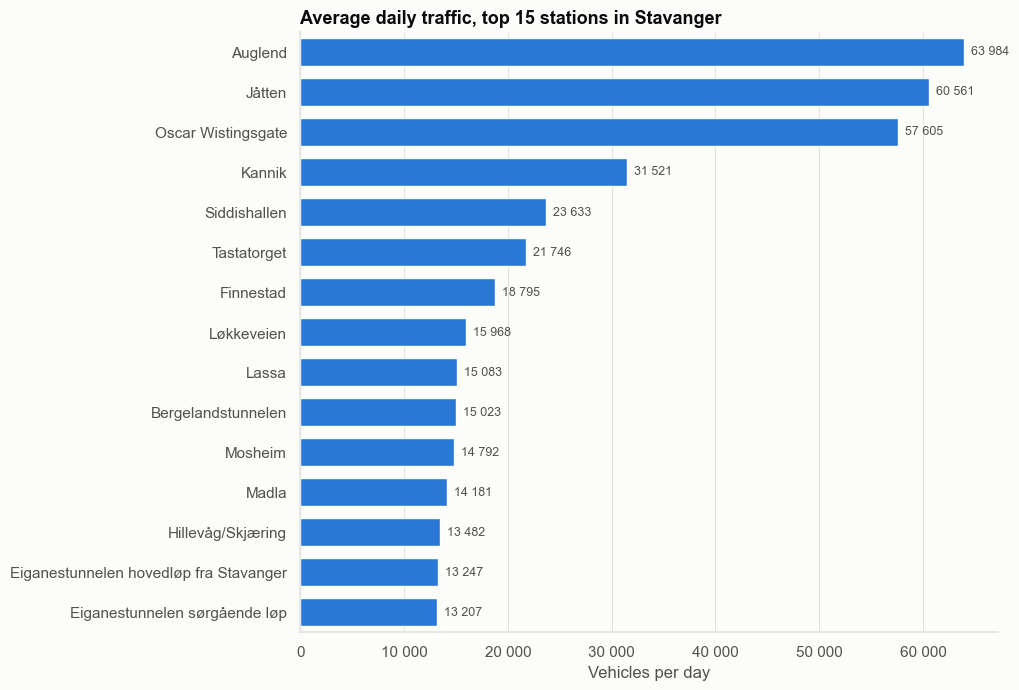

Saved figures\traffic\01_station_adt.png


In [13]:
TOP_N = 15
adt = (daily.groupby("name")["volume"].mean()
       .sort_values(ascending=False).head(TOP_N).reset_index())

fig, ax = plt.subplots(figsize=(9, 0.42 * len(adt) + 1.5))
sns.barplot(data=adt, y="name", x="volume", color=SERIES_BLUE, saturation=1, width=0.7, ax=ax)
for bar, value in zip(ax.patches, adt["volume"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  {value:,.0f}".replace(",", " "), va="center", fontsize=9, color=TEXT_SECONDARY)
ax.set(title=f"Average daily traffic, top {len(adt)} stations in Stavanger",
       xlabel="Vehicles per day", ylabel="")
ax.grid(axis="y", visible=False)
thousands(ax, "x")
save(fig, "01_station_adt")

### 7.2 How does traffic change over the day?
**Chart:** mean vehicles per hour for weekdays and weekends, averaged over all stations.
**How to read it:** weekdays usually show two commuter peaks (morning and afternoon). Weekends show one broad midday hump. Rush hours combine high volume with time pressure, which is a known accident risk factor. Compare these peaks with accident times in the accident analysis.

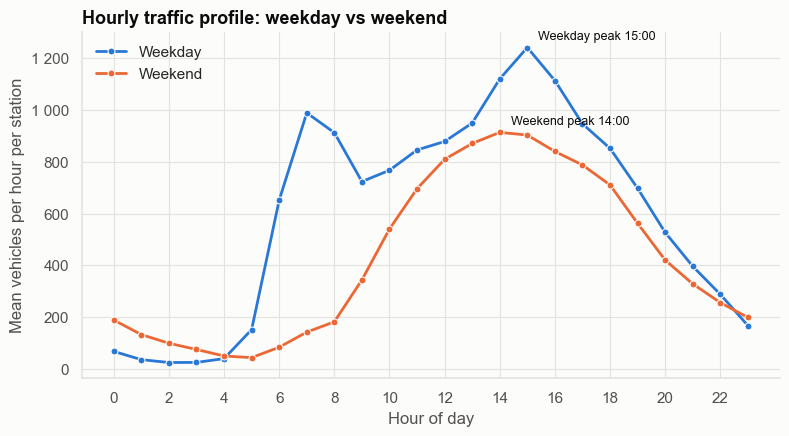

Saved figures\traffic\02_hourly_profile.png


In [14]:
profile = (hourly.assign(day_type=hourly["is_weekend"].map({False: "Weekday", True: "Weekend"}))
           .groupby(["day_type", "hour"])["volume"].mean().reset_index())

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=profile, x="hour", y="volume", hue="day_type",
             palette={"Weekday": SERIES_BLUE, "Weekend": SERIES_ORANGE},
             marker="o", markersize=5, ax=ax)
for label in ("Weekday", "Weekend"):
    peak = profile[profile["day_type"] == label].nlargest(1, "volume").iloc[0]
    ax.annotate(f"{label} peak {int(peak['hour']):02d}:00", (peak["hour"], peak["volume"]),
                xytext=(8, 6), textcoords="offset points", fontsize=9, color=TEXT_PRIMARY)
ax.set(title="Hourly traffic profile: weekday vs weekend",
       xlabel="Hour of day", ylabel="Mean vehicles per hour per station")
ax.set_xticks(range(0, 24, 2))
ax.legend(title="")
thousands(ax)
save(fig, "02_hourly_profile")

### 7.3 When exactly is Stavanger busiest?
**Chart:** heatmap of mean volume for every weekday and hour.
**How to read it:** darker cells mean more traffic. This shows the full weekly rhythm in one picture, for example whether Friday afternoons start earlier than other weekdays. The same weekday by hour grid can be drawn for accidents later, so the two patterns can be compared side by side.

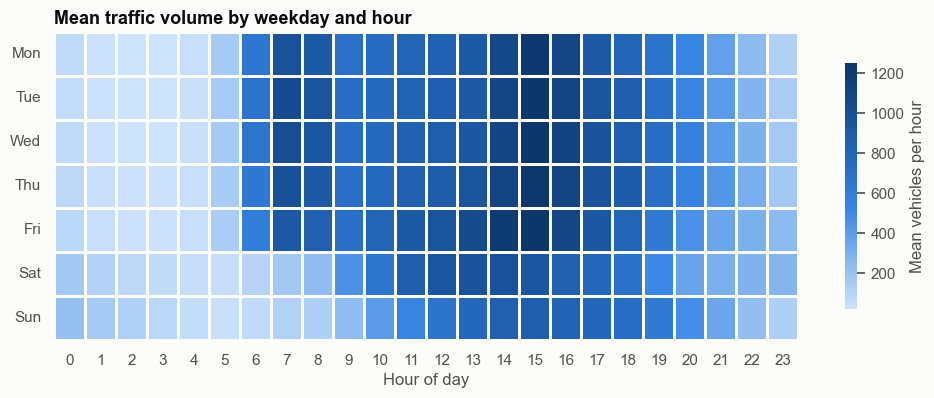

Saved figures\traffic\03_weekday_hour_heatmap.png


In [15]:
pivot = hourly.pivot_table(index="weekday", columns="hour", values="volume",
                           aggfunc="mean", observed=False)

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(pivot, cmap=SEQUENTIAL_BLUE, linewidths=1, linecolor=SURFACE,
            cbar_kws={"label": "Mean vehicles per hour", "shrink": 0.8}, ax=ax)
ax.set(title="Mean traffic volume by weekday and hour", xlabel="Hour of day", ylabel="")
ax.tick_params(axis="y", rotation=0)
save(fig, "03_weekday_hour_heatmap")

### 7.4 How has traffic developed over time?
**Chart:** mean daily traffic per station, with a 7-day rolling average.
**How to read it:** the light line shows the day-to-day values, including the weekly weekday/weekend swing. The dark line smooths this out to show the trend. Look for holiday dips (Easter, July, Christmas) and any long-term growth or decline.

Only stations with data on at least 90% of days are used. Otherwise a station switching on or off would look like a jump in traffic.

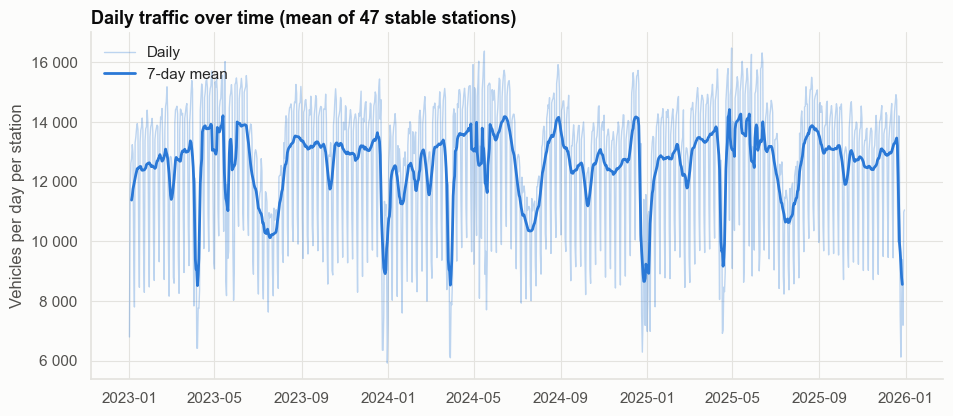

Saved figures\traffic\04_daily_trend.png


In [16]:
days_per_station = daily.groupby("point_id")["date"].nunique()
stable_ids = days_per_station[days_per_station >= 0.9 * daily["date"].nunique()].index
trend = daily[daily["point_id"].isin(stable_ids)].groupby("date")["volume"].mean().sort_index()
rolling = trend.rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(trend.index, trend.values, color=SERIES_BLUE, alpha=0.3, linewidth=1, label="Daily")
ax.plot(rolling.index, rolling.values, color=SERIES_BLUE, label="7-day mean")
ax.set(title=f"Daily traffic over time (mean of {len(stable_ids)} stable stations)",
       xlabel="", ylabel="Vehicles per day per station")
ax.legend(loc="upper left")
thousands(ax)
save(fig, "04_daily_trend")

### 7.5 Is there a seasonal pattern?
**Chart:** mean daily traffic per calendar month. The black lines are 95% confidence intervals.
**How to read it:** months with overlapping intervals are not clearly different. Seasonality matters for accidents in two ways: summer brings holiday and tourist traffic, while winter brings darkness, ice and snow at lower volumes. Adding weather data later helps separate those effects.

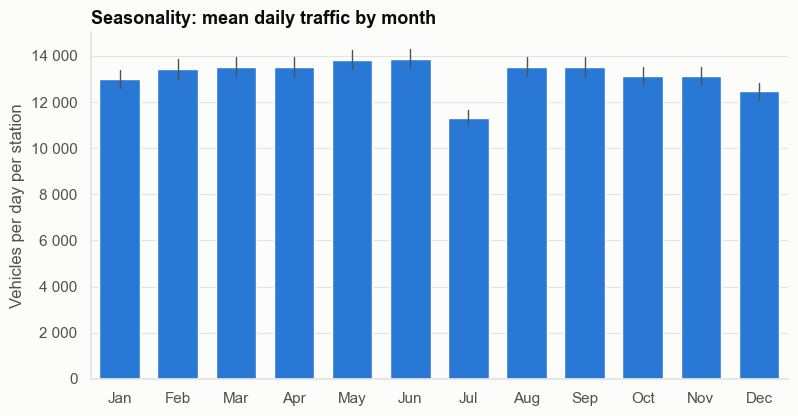

Saved figures\traffic\05_monthly_pattern.png


In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=daily, x="month", y="volume", color=SERIES_BLUE, saturation=1, width=0.7,
            errorbar=("ci", 95), err_kws={"color": TEXT_SECONDARY, "linewidth": 1}, ax=ax)
ax.set_xticks(range(12))
ax.set_xticklabels(MONTH_LABELS)
ax.set(title="Seasonality: mean daily traffic by month",
       xlabel="", ylabel="Vehicles per day per station")
thousands(ax)
save(fig, "05_monthly_pattern")

### 7.6 How much does daily traffic vary within each weekday?
**Chart:** box plot of daily volume per station for each weekday.
**How to read it:** the box holds the middle 50% of days and the line inside it is the median. Dots are unusual days, often public holidays or road closures. Wide boxes are mainly caused by differences between stations, since big and small roads are mixed together here.

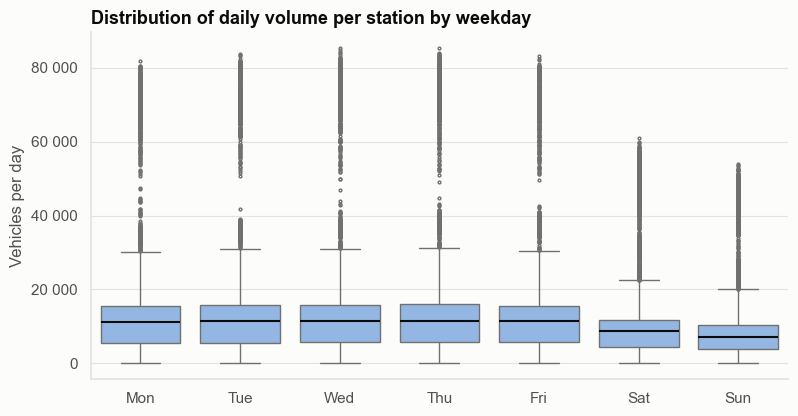

Saved figures\traffic\06_weekday_distribution.png


In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=daily, x="weekday", y="volume", color="#86b6ef", linewidth=1, fliersize=2,
            medianprops={"color": TEXT_PRIMARY, "linewidth": 1.5}, ax=ax)
ax.set(title="Distribution of daily volume per station by weekday",
       xlabel="", ylabel="Vehicles per day")
thousands(ax)
save(fig, "06_weekday_distribution")

### 7.7 Where do heavy vehicles drive?
**Chart:** share of vehicles 5.6 m or longer at each station.
**How to read it:** a high share points to freight routes (harbour, industrial areas, through-traffic on E39). Heavy vehicles are involved in a large share of serious accidents, so this is a useful feature for the model. The chart is skipped if the API did not return length data.

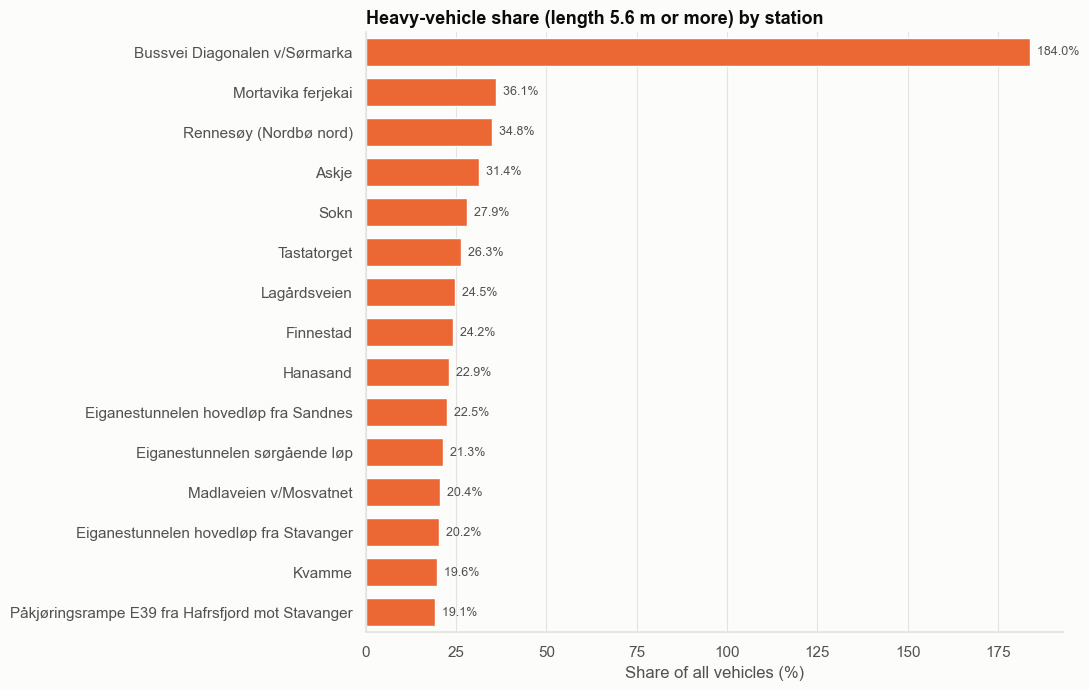

Saved figures\traffic\07_heavy_vehicle_share.png


In [19]:
if daily["heavy_volume"].fillna(0).sum() == 0:
    print("No vehicle-length data available, chart skipped.")
else:
    heavy = (daily.groupby("name")[["heavy_volume", "volume"]].sum()
             .assign(share=lambda d: 100 * d["heavy_volume"] / d["volume"])
             .sort_values("share", ascending=False).head(TOP_N).reset_index())
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(heavy) + 1.5))
    sns.barplot(data=heavy, y="name", x="share", color=SERIES_ORANGE, saturation=1,
                width=0.7, ax=ax)
    for bar, value in zip(ax.patches, heavy["share"]):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {value:.1f}%",
                va="center", fontsize=9, color=TEXT_SECONDARY)
    ax.set(title="Heavy-vehicle share (length 5.6 m or more) by station",
           xlabel="Share of all vehicles (%)", ylabel="")
    ax.grid(axis="y", visible=False)
    save(fig, "07_heavy_vehicle_share")

### 7.8 Where are the stations located?
**Chart:** station positions by latitude and longitude. Larger and darker dots mean higher ADT.
**How to read it:** this is a quick spatial overview without a background map. For the final report, the same coordinates can be drawn on a real map with `geopandas` or `folium` and overlaid with accident locations.

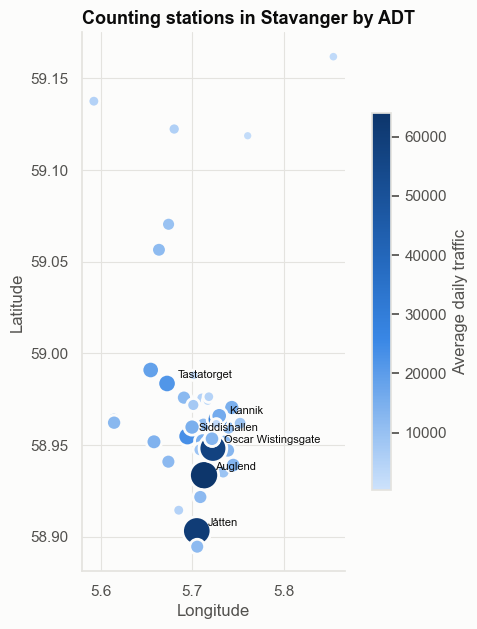

Saved figures\traffic\08_station_map.png


In [20]:
station_adt = daily.groupby("point_id")["volume"].mean().rename("adt")
geo = points.merge(station_adt, on="point_id").dropna(subset=["lat", "lon"])

fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(geo["lon"], geo["lat"], s=40 + geo["adt"] / geo["adt"].max() * 400,
                c=geo["adt"], cmap=SEQUENTIAL_BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
for _, r in geo.nlargest(6, "adt").iterrows():
    ax.annotate(r["name"], (r["lon"], r["lat"]), xytext=(8, 4),
                textcoords="offset points", fontsize=8, color=TEXT_PRIMARY)
fig.colorbar(sc, ax=ax, shrink=0.7).set_label("Average daily traffic")
ax.set(title="Counting stations in Stavanger by ADT", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect(1 / 0.5)  # Corrects the longitude stretch at about 59 degrees north
save(fig, "08_station_map")

## 8. Key insights

The cell below computes the headline numbers behind the charts. Use them in the report text, and update the interpretation once you have run the notebook on the full period.

In [21]:
weekday_adt = daily.loc[~daily["weekday"].isin(["Sat", "Sun"]), "volume"].mean()
weekend_adt = daily.loc[daily["weekday"].isin(["Sat", "Sun"]), "volume"].mean()
peak_hours = (hourly[~hourly["is_weekend"]].groupby("hour")["volume"].mean()
              .nlargest(2).index.sort_values())
monthly = daily.groupby("month")["volume"].mean()

summary = pd.Series({
    "Stations analysed": daily["point_id"].nunique(),
    "Days covered": daily["date"].nunique(),
    "Weekday ADT per station": round(weekday_adt),
    "Weekend ADT per station": round(weekend_adt),
    "Weekend as % of weekday": f"{100 * weekend_adt / weekday_adt:.0f}%",
    "Weekday peak hours": ", ".join(f"{h:02d}:00" for h in peak_hours),
    "Busiest month": MONTH_LABELS[monthly.idxmax() - 1],
    "Quietest month": MONTH_LABELS[monthly.idxmin() - 1],
    "Busiest station": daily.groupby("name")["volume"].mean().idxmax(),
}, name="Value")
summary.to_frame()

,Value
Stations analysed,52
Days covered,1095
Weekday ADT per station,14401
Weekend ADT per station,10168
Weekend as % of weekday,71%
Weekday peak hours,"14:00, 15:00"
Busiest month,Jun
Quietest month,Jul
Busiest station,Auglend


## 9. Save outputs

| File | Content | Use |
|---|---|---|
| `data/processed/traffic_stations.csv` | One row per station with coordinates and road category | Spatial join with accident locations |
| `data/processed/traffic_hourly_clean.csv` | Cleaned hourly volumes with calendar features | Hour-level analysis |
| `data/processed/traffic_daily.csv` | Daily volume per station | Main traffic feature table for the ML model |

**Next step:** load the accident data (for example from the Statens vegvesen accident register or SSB), match each accident to the nearest counting station and date, and use `volume`, `heavy_volume`, `hour`, `weekday` and `month` as model features. Accidents per million vehicles is a fairer risk measure than raw accident counts.

In [22]:
points.to_csv(PROCESSED_DIR / "traffic_stations.csv", index=False)
hourly.to_csv(PROCESSED_DIR / "traffic_hourly_clean.csv", index=False)
daily.to_csv(PROCESSED_DIR / "traffic_daily.csv", index=False)
for f in sorted(PROCESSED_DIR.glob("traffic_*.csv")):
    print(f"{f.relative_to(PROJECT_ROOT)}  ({f.stat().st_size / 1e6:.1f} MB)")

data\processed\traffic_daily.csv  (4.0 MB)
data\processed\traffic_hourly_clean.csv  (185.3 MB)
data\processed\traffic_stations.csv  (0.0 MB)
